# BÀI 5: THỰC HÀNH CNN VỚI PYTORCH TRÊN DỮ LIỆU CIFAR-10
### LeNet → Regularization → Data augmentation → VGG / Inception / ResNet

**Mục tiêu thực hành:**
1. Viết **ba hàm dùng chung**: `train_one_epoch()`, `evaluate()`, `test_model()` trên bộ dữ liệu ảnh màu RGB **CIFAR-10** (3 kênh, kích thước $32 \times 32$, 10 lớp, điều chỉnh `in_channels=3`).
2. Quan sát **đầy đủ log mọi epoch** của **từng thí nghiệm riêng biệt** trước khi tổng hợp.
3. Thực nghiệm regularization: **Dropout, AdamW weight decay**; augmentation; thay activation, pooling, BatchNorm của LeNet với dữ liệu màu.
4. Tự xây dựng ba kiến trúc Modern CNN thu nhỏ: **VGG, Inception, ResNet** cho ảnh CIFAR-10.
5. **Phân tích các mẫu dự đoán sai trên validation** sau mỗi thí nghiệm: ảnh sai, nhãn thật/dự đoán, độ tin cậy, cặp nhãn dễ nhầm.
6. So sánh bằng validation; chỉ **test một lần** sau khi chọn checkpoint và mô hình.

> **Dữ liệu đã chạy:** `DATA_SOURCE='cifar10'` tải trực tiếp qua `torchvision.datasets.CIFAR10`.

**Framework:** PyTorch; sklearn; matplotlib.

## Cấu hình và thư viện


In [1]:
import os, time, random, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix

SEED = 42
DATA_SOURCE = "cifar10"
EPOCHS = 16
BATCH_SIZE = 64
LR = 1e-3

def seed_all(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

seed_all()
torch.set_num_threads(min(2, os.cpu_count() or 2))
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch {torch.__version__} | Device = {DEVICE} | Seed = {SEED}")
print(f"DATA_SOURCE = {DATA_SOURCE} | EPOCHS = {EPOCHS}")


PyTorch 2.15.0+cpu | Device = cpu | Seed = 42
DATA_SOURCE = cifar10 | EPOCHS = 16


## 1. Dữ liệu CIFAR-10 và chia train/validation/test 

**CIFAR-10:** 50.000 ảnh train + 10.000 ảnh test, 10 lớp đối tượng tự nhiên (động vật và phương tiện), kích thước gốc $32\times 32$ với 3 kênh màu RGB. Ta trích **5.000 ảnh từ tập train làm validation** (45.000 train / 5.000 validation), giữ nguyên 10.000 ảnh test chính thức.


100.0%


Train/Val/Test: 45000/5000/10000
Tensor ảnh = (3, 32, 32); lớp = 10 | Tên lớp: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


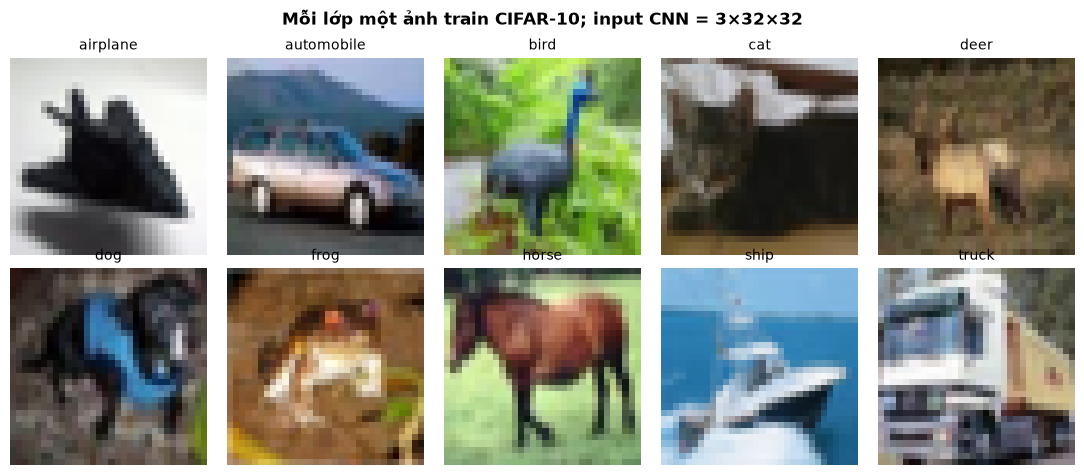

In [2]:
CLASS_NAMES_CIFAR10 = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]
CLASS_NAMES = CLASS_NAMES_CIFAR10

# Mean và Std chuẩn của CIFAR-10 cho 3 kênh RGB
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD = (0.2023, 0.1994, 0.2010)

# Tải dữ liệu gốc (dạng ToTensor [0, 1]) để chia tập và trực quan hóa
raw_train_dataset = datasets.CIFAR10(root="./data", train=True, download=True, transform=transforms.ToTensor())
raw_test_dataset = datasets.CIFAR10(root="./data", train=False, download=True, transform=transforms.ToTensor())

VAL_SIZE = 5_000
TRAIN_SIZE = len(raw_train_dataset) - VAL_SIZE

seed_all(SEED)
indices = list(range(len(raw_train_dataset)))
train_indices = indices[:TRAIN_SIZE]
val_indices = indices[TRAIN_SIZE:]

print(f"Train/Val/Test: {TRAIN_SIZE}/{VAL_SIZE}/{len(raw_test_dataset)}")
print(f"Tensor ảnh = (3, 32, 32); lớp = {len(CLASS_NAMES)} | Tên lớp: {CLASS_NAMES}")

# Hiển thị mỗi lớp một ảnh mẫu trên tập Train 
fig, axes = plt.subplots(2, 5, figsize=(11, 4.8))
for c, ax in enumerate(axes.flat):
    idx = next(i for i in train_indices if raw_train_dataset.targets[i] == c)
    img, _ = raw_train_dataset[idx]
    ax.imshow(img.permute(1, 2, 0).numpy())
    ax.set_title(CLASS_NAMES[c], fontsize=10)
    ax.axis("off")
fig.suptitle("Mỗi lớp một ảnh train CIFAR-10; input CNN = 3×32×32", weight="bold")
plt.tight_layout()
plt.show()


## 2. Data augmentation và DataLoader

Với ảnh màu tự nhiên CIFAR-10 (động vật, phương tiện), ta áp dụng các phép biến đổi phù hợp ngữ nghĩa: `RandomCrop(32, padding=4)` (dịch chuyển nhẹ), `RandomHorizontalFlip()` (lật ngang) và `ColorJitter` (điều chỉnh nhẹ độ sáng/tương phản).

**Phân biệt** augmentation và regularization: augmentation thay đổi dữ liệu đầu vào khi học; Dropout làm ngẫu nhiên kích hoạt của neuron; weight decay tạo xu hướng giảm độ lớn trọng số. Cả ba có thể hỗ trợ tổng quát hóa, nhưng là các cơ chế khác nhau.


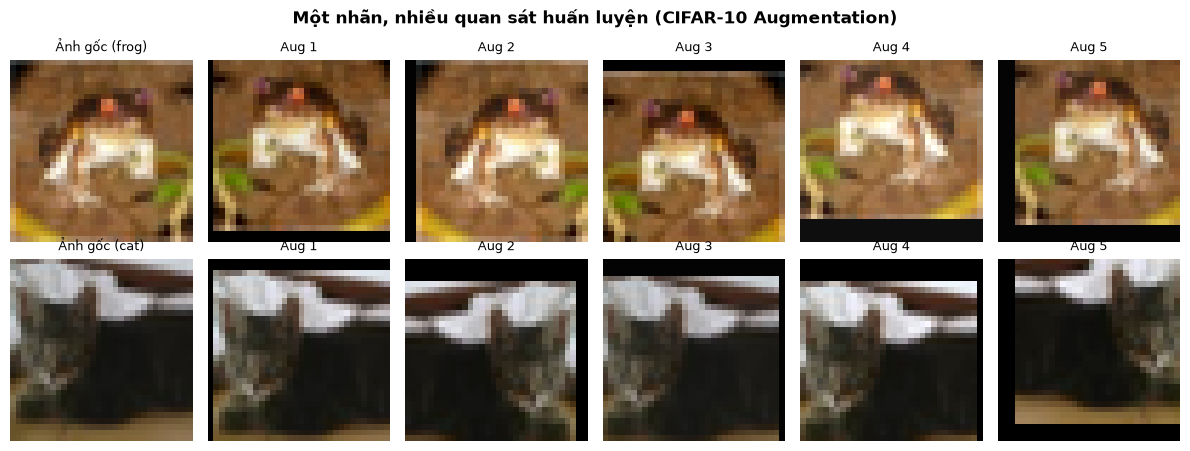

Một mini-batch: (64, 3, 32, 32) | nhãn: (64,)


In [3]:
class ImageTensorDataset(torch.utils.data.Dataset):
    def __init__(self, base_dataset, indices, augment=False):
        self.base_dataset = base_dataset
        self.indices = indices
        self.augment = augment
        self.augmenter = transforms.Compose([
            transforms.RandomCrop(32, padding=4),
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.ColorJitter(brightness=0.15, contrast=0.15),
        ])
        self.normalizer = transforms.Normalize(CIFAR_MEAN, CIFAR_STD)

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        img, label = self.base_dataset[self.indices[idx]]
        if self.augment:
            img = self.augmenter(img).clamp(0, 1)
        img = self.normalizer(img)
        return img, label

train_clean_ds = ImageTensorDataset(raw_train_dataset, train_indices, augment=False)
train_aug_ds   = ImageTensorDataset(raw_train_dataset, train_indices, augment=True)
val_ds         = ImageTensorDataset(raw_train_dataset, val_indices, augment=False)
test_ds        = ImageTensorDataset(raw_test_dataset, list(range(len(raw_test_dataset))), augment=False)

train_clean_loader = DataLoader(train_clean_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
train_plain_loader = DataLoader(train_clean_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
train_aug_loader   = DataLoader(train_aug_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader         = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader        = DataLoader(test_ds, batch_size=128, shuffle=False, num_workers=0)

# Minh họa trực quan Data Augmentation (Ảnh gốc + 5 biến thể Aug 1..5 giống Phần 2 bài mẫu)
seed_all()
fig, axs = plt.subplots(2, 6, figsize=(12, 4.6))
for row, sample_idx in enumerate([0, 9]):  # Lấy 2 ảnh tiêu biểu (frog, cat)
    original, lbl = raw_train_dataset[train_indices[sample_idx]]
    axs[row, 0].imshow(original.permute(1, 2, 0).numpy())
    axs[row, 0].set_title(f"Ảnh gốc ({CLASS_NAMES[lbl]})", fontsize=9)
    for col in range(1, 6):
        aug_img = train_aug_ds.augmenter(original).clamp(0, 1)
        axs[row, col].imshow(aug_img.permute(1, 2, 0).numpy())
        axs[row, col].set_title(f"Aug {col}", fontsize=9)
    for ax in axs[row]:
        ax.axis("off")
plt.suptitle("Một nhãn, nhiều quan sát huấn luyện (CIFAR-10 Augmentation)", weight="bold")
plt.tight_layout()
plt.show()

xb, yb = next(iter(train_plain_loader))
print("Một mini-batch:", tuple(xb.shape), "| nhãn:", tuple(yb.shape))


## Công thức tổng quát tính kích thước đầu ra trong CNN

### 1. Ký hiệu chung

Giả sử tensor đầu vào có kích thước:

$$
X \in \mathbb{R}^{N \times C_{\text{in}} \times H_{\text{in}} \times W_{\text{in}}}
$$

Trong đó:

- $N$: Batch size (số ảnh trong một batch).
- $C_{\text{in}}$: Số kênh đầu vào.
- $H_{\text{in}}, W_{\text{in}}$: Chiều cao và chiều rộng đầu vào.
- $C_{\text{out}}$: Số kênh đầu ra (số filters).
- $K$: Kích thước kernel.
- $S$: Stride (bước dịch chuyển).
- $P$: Padding (số pixel thêm vào mỗi phía).
- $D$: Dilation (độ giãn của kernel).
- $\lfloor x \rfloor$: Phép làm tròn xuống.

### 2. Convolution 2D (`nn.Conv2d`)

Công thức tổng quát:

$$
\boxed{
H_{\text{out}} =
\left\lfloor
\frac{H_{\text{in}} + 2P_h - D_h(K_h-1)-1}{S_h}+1
\right\rfloor
}
$$

$$
\boxed{
W_{\text{out}} =
\left\lfloor
\frac{W_{\text{in}} + 2P_w - D_w(K_w-1)-1}{S_w}+1
\right\rfloor
}
$$

Kích thước tensor đầu ra:

$$
\boxed{
(N,C_{\text{out}},H_{\text{out}},W_{\text{out}})
}
$$

**Trường hợp thường gặp:** $D=1$, kernel vuông, stride và padding giống nhau trên hai chiều:

$$
\boxed{
H_{\text{out}} =
\left\lfloor
\frac{H_{\text{in}}+2P-K}{S}
\right\rfloor+1
}
$$

Tương tự cho $W_{\text{out}}$.

### 3. Pooling (`nn.MaxPool2d`, `nn.AvgPool2d`)

Với pooling thông dụng ($D=1$, `ceil_mode=False`), kích thước không gian đầu ra:

$$
\boxed{
H_{\text{out}} =
\left\lfloor
\frac{H_{\text{in}}+2P-K}{S}
\right\rfloor+1
}
$$

$$
\boxed{
W_{\text{out}} =
\left\lfloor
\frac{W_{\text{in}}+2P-K}{S}
\right\rfloor+1
}
$$

Kích thước tensor:

$$
\boxed{
(N,C_{\text{in}},H_{\text{out}},W_{\text{out}})
}
$$

Pooling không thay đổi số kênh.


## 3. LeNet: Thay đổi in_channels = 3 cho ảnh màu RGB


In [4]:
class LeNet(nn.Module):
    def __init__(self, activation="tanh", pool="avg", batchnorm=False, dropout=0.0, n_classes=10):
        super().__init__()
        make_act = nn.Tanh if activation == "tanh" else nn.ReLU
        make_pool = nn.AvgPool2d if pool == "avg" else nn.MaxPool2d
        self.features = nn.Sequential(
            nn.Conv2d(3, 6, kernel_size=5), # Đổi in_channels từ 1 sang 3 do CIFAR-10 là ảnh màu RGB
            nn.BatchNorm2d(6) if batchnorm else nn.Identity(),
            make_act(), make_pool(2),
            nn.Conv2d(6, 16, kernel_size=5),
            nn.BatchNorm2d(16) if batchnorm else nn.Identity(),
            make_act(), make_pool(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(16 * 5 * 5, 120), make_act(), nn.Dropout(dropout),
            nn.Linear(120, 84), make_act(), nn.Dropout(dropout), nn.Linear(84, n_classes)
        )
    def forward(self, x):
        return self.classifier(self.features(x))

def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

baseline = LeNet()
with torch.no_grad():
    out = baseline(torch.zeros(4, 3, 32, 32))
print('LeNet output:', tuple(out.shape), '| tham số:', f'{count_params(baseline):,}')


LeNet output: (4, 10) | tham số: 62,006


## 4. Modern CNN thu nhỏ (VGG, Inception, ResNet) với in_channels = 3


In [5]:
def vgg_block(cin, cout, nconv=2):
    layers = []
    for j in range(nconv):
        layers += [nn.Conv2d(cin if j == 0 else cout, cout, 3, padding=1, bias=False),
                   nn.BatchNorm2d(cout), nn.ReLU()]
    return nn.Sequential(*layers, nn.MaxPool2d(2))

class VGGTiny(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.features = nn.Sequential(vgg_block(3, 16), vgg_block(16, 32), vgg_block(32, 64)) # in_channels = 3
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                                  nn.Linear(64, 64), nn.ReLU(), nn.Dropout(.25),
                                  nn.Linear(64, n_classes))
    def forward(self, x): return self.head(self.features(x))

class InceptionBlock(nn.Module):
    def __init__(self, cin, branch_channels):
        super().__init__()
        c = branch_channels
        def cbr(a, b, k, p=0):
            return [nn.Conv2d(a, b, k, padding=p, bias=False), nn.BatchNorm2d(b), nn.ReLU()]
        self.b1 = nn.Sequential(*cbr(cin, c, 1))
        self.b3 = nn.Sequential(*cbr(cin, c, 1), *cbr(c, c, 3, p=1))
        self.b5 = nn.Sequential(*cbr(cin, c, 1), *cbr(c, c, 5, p=2))
        self.bp = nn.Sequential(nn.MaxPool2d(3, stride=1, padding=1), *cbr(cin, c, 1))
    def forward(self, x):
        return torch.cat([self.b1(x), self.b3(x), self.b5(x), self.bp(x)], dim=1)

class InceptionTiny(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), # in_channels = 3
            InceptionBlock(16, 8), nn.MaxPool2d(2),
            InceptionBlock(32, 16), nn.MaxPool2d(2),
            InceptionBlock(64, 16))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(.25), nn.Linear(64, n_classes))
    def forward(self, x): return self.head(self.features(x))

class ResidualBlock(nn.Module):
    def __init__(self, cin, cout, stride=1):
        super().__init__()
        self.residual = nn.Sequential(
            nn.Conv2d(cin, cout, 3, stride=stride, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(),
            nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout))
        self.skip = (nn.Identity() if cin == cout and stride == 1 else
                     nn.Sequential(nn.Conv2d(cin, cout, 1, stride=stride, bias=False), nn.BatchNorm2d(cout)))
        self.act = nn.ReLU()
    def forward(self, x): return self.act(self.residual(x) + self.skip(x))

class ResNetTiny(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, 16, 3, padding=1, bias=False), nn.BatchNorm2d(16), nn.ReLU()) # in_channels = 3
        self.blocks = nn.Sequential(ResidualBlock(16, 16), ResidualBlock(16, 32, stride=2),
                                    ResidualBlock(32, 32), ResidualBlock(32, 64, stride=2), ResidualBlock(64, 64))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(64, n_classes))
    def forward(self, x): return self.head(self.blocks(self.stem(x)))


## 5. Bộ hàm huấn luyện và đánh giá chuẩn hóa


In [6]:
def train_one_epoch(model, dataloader, optimizer, criterion, device):
    model.train()
    total_loss = 0.0
    n_correct = 0
    n_samples = 0
    for x, y in dataloader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()
        batch_size = y.size(0)
        total_loss += loss.item() * batch_size
        n_correct += (logits.argmax(dim=1) == y).sum().item()
        n_samples += batch_size
    return {"loss": total_loss / n_samples, "accuracy": n_correct / n_samples, "n_samples": n_samples}

@torch.inference_mode()
def evaluate(model, dataloader, criterion, device, return_predictions=False):
    model.eval()
    total_loss = 0.0
    n_correct = 0
    n_samples = 0
    y_true, y_pred = [], []
    for x, y in dataloader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        loss = criterion(logits, y)
        preds = logits.argmax(dim=1)
        batch_size = y.size(0)
        total_loss += loss.item() * batch_size
        n_correct += (preds == y).sum().item()
        n_samples += batch_size
        if return_predictions:
            y_true.extend(y.cpu().tolist())
            y_pred.extend(preds.cpu().tolist())
    metrics = {"loss": total_loss / n_samples, "accuracy": n_correct / n_samples, "n_samples": n_samples}
    if return_predictions:
        metrics["y_true"] = np.asarray(y_true, dtype=np.int64)
        metrics["y_pred"] = np.asarray(y_pred, dtype=np.int64)
    return metrics

def test_model(model, dataloader, criterion, device, class_names):
    raw = evaluate(model, dataloader, criterion, device, return_predictions=True)
    labels = list(range(len(class_names)))
    cm = confusion_matrix(raw["y_true"], raw["y_pred"], labels=labels)
    report = classification_report(raw["y_true"], raw["y_pred"], labels=labels, target_names=class_names, zero_division=0)
    return {"loss": raw["loss"], "accuracy": raw["accuracy"], "n_samples": raw["n_samples"],
            "y_true": raw["y_true"], "y_pred": raw["y_pred"], "confusion_matrix": cm, "classification_report": report}

criterion = nn.CrossEntropyLoss()
RESULTS, HISTORIES, BEST_MODELS, VAL_ANALYSES = [], {}, {}, {}

def fit_model(model, train_loader, train_monitor_loader, val_loader, optimizer, criterion, device, epochs, run_name):
    history = []
    best_val_loss, best_state, best_epoch = float("inf"), None, 0
    print("epoch | opt_loss | train_loss | train_acc | val_loss | val_acc | best")
    print("-" * 78)
    for epoch in range(1, epochs + 1):
        opt = train_one_epoch(model, train_loader, optimizer, criterion, device)
        train = evaluate(model, train_monitor_loader, criterion, device)
        val = evaluate(model, val_loader, criterion, device)
        history.append({"epoch": epoch, "opt_loss": opt["loss"], "opt_acc": opt["accuracy"],
                        "train_loss": train["loss"], "train_acc": train["accuracy"],
                        "val_loss": val["loss"], "val_acc": val["accuracy"]})
        improved = val["loss"] < best_val_loss
        if improved:
            best_val_loss = val["loss"]
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch
        print(f"{epoch:02d}/{epochs:02d} | {opt['loss']:.4f}   | {train['loss']:.4f}     | {train['accuracy']:.2%}  | {val['loss']:.4f}   | {val['accuracy']:.2%}  | {'*' if improved else ''}", flush=True)
    model.load_state_dict(best_state)
    return model, pd.DataFrame(history), best_epoch

def plot_single_run(name, history):
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.6))
    axes[0].plot(history.epoch, history.train_acc * 100, label="Train sạch")
    axes[0].plot(history.epoch, history.val_acc * 100, label="Validation")
    axes[1].plot(history.epoch, history.train_loss, label="Train sạch")
    axes[1].plot(history.epoch, history.val_loss, label="Validation")
    axes[0].set(xlabel="Epoch", ylabel="Accuracy (%)", title="Accuracy")
    axes[1].set(xlabel="Epoch", ylabel="Cross-entropy loss", title="Loss")
    for ax in axes: ax.grid(alpha=.25); ax.legend()
    fig.suptitle(f"Learning curves: {name}", weight="bold")
    plt.tight_layout(); plt.show()

@torch.inference_mode()
def collect_validation_predictions(model, dataloader, device):
    model.eval()
    records, stored_images = [], []
    sample_index = 0
    for images, labels in dataloader:
        logits = model(images.to(device))
        probabilities = torch.softmax(logits, dim=1)
        confidence, predictions = probabilities.max(dim=1)
        p_true = probabilities.gather(1, labels.to(device).unsqueeze(1)).squeeze(1)
        stored_images.append(images.detach().cpu().clone())
        for true_label, pred_label, score, true_score in zip(labels.cpu().tolist(), predictions.cpu().tolist(), confidence.cpu().tolist(), p_true.cpu().tolist()):
            records.append({"sample_index": sample_index, "true_label": int(true_label), "pred_label": int(pred_label), "confidence": float(score), "p_true": float(true_score), "correct": int(true_label) == int(pred_label)})
            sample_index += 1
    return pd.DataFrame(records), torch.cat(stored_images, dim=0)

def analyze_validation_errors(model, dataloader, class_names, device, *, mean=0.0, std=1.0, run_name="Model", max_examples=6, show_plot=True):
    details, images = collect_validation_predictions(model, dataloader, device)
    wrong = details.loc[~details["correct"]].copy()
    n_total, n_errors = len(details), len(wrong)
    print(f"\n--- PHÂN TÍCH MẪU SAI TRÊN VALIDATION — {run_name} ---")
    print(f"Sai {n_errors}/{n_total} mẫu ({n_errors/n_total:.2%}); đúng {(n_total-n_errors)/n_total:.2%}.")
    return {"details": details, "images": images, "n_errors": n_errors, "n_total": n_total}

def run_experiment(name, model_factory, use_aug=False, wd=0.0, epochs=EPOCHS, seed=SEED, show_plot=True):
    if name in HISTORIES: raise ValueError(f"Tên thí nghiệm đã tồn tại: {name}")
    seed_all(seed)
    model = model_factory().to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=wd)
    dl_train = train_aug_loader if use_aug else train_plain_loader
    start = time.perf_counter()
    print(f"\n=== {name} ===")
    print(f"params={count_params(model):,} | augmentation={use_aug} | weight_decay={wd:g} | lr={LR} | epochs={epochs}")
    model, history, best_epoch = fit_model(model, dl_train, train_clean_loader, val_loader, optimizer, criterion, DEVICE, epochs, run_name=name)
    seconds = time.perf_counter() - start
    train = evaluate(model, train_clean_loader, criterion, DEVICE)
    val = evaluate(model, val_loader, criterion, DEVICE)
    row = {"model": name, "parameters": count_params(model), "best_epoch": best_epoch, "train_acc": train["accuracy"], "val_acc": val["accuracy"], "val_loss": val["loss"], "gap": train["accuracy"] - val["accuracy"], "seconds": round(seconds, 2)}
    HISTORIES[name] = history
    BEST_MODELS[name] = copy.deepcopy(model).cpu()
    RESULTS.append(row)
    print(f"\nCHECKPOINT chọn: epoch {best_epoch:02d} | val_acc={val['accuracy']:.2%} | val_loss={val['loss']:.4f}")
    if show_plot: plot_single_run(name, history)
    analysis = analyze_validation_errors(model, val_loader, CLASS_NAMES, DEVICE, run_name=name, show_plot=False)
    row["val_errors"] = analysis["n_errors"]
    VAL_ANALYSES[name] = analysis
    return row


## 6. LeNet — Chạy thí nghiệm E0–E4



=== E0 LeNet Tanh+Avg ===
params=62,006 | augmentation=False | weight_decay=0 | lr=0.001 | epochs=16
epoch | opt_loss | train_loss | train_acc | val_loss | val_acc | best
------------------------------------------------------------------------------
01/16 | 1.7252   | 1.5393     | 45.36%  | 1.5600   | 44.36%  | *
02/16 | 1.4738   | 1.3645     | 51.25%  | 1.3987   | 49.38%  | *
03/16 | 1.3408   | 1.2519     | 55.33%  | 1.3069   | 52.40%  | *
04/16 | 1.2570   | 1.1642     | 58.40%  | 1.2494   | 55.00%  | *
05/16 | 1.1938   | 1.1209     | 60.04%  | 1.2419   | 55.08%  | *
06/16 | 1.1389   | 1.0826     | 61.52%  | 1.2399   | 55.60%  | *
07/16 | 1.0959   | 1.0321     | 63.39%  | 1.2231   | 56.74%  | *
08/16 | 1.0554   | 1.0068     | 64.22%  | 1.2339   | 55.60%  | 
09/16 | 1.0210   | 0.9570     | 65.95%  | 1.2123   | 57.36%  | *
10/16 | 0.9869   | 0.9247     | 67.54%  | 1.2262   | 56.90%  | 
11/16 | 0.9606   | 0.8907     | 68.68%  | 1.2159   | 57.58%  | 
12/16 | 0.9289   | 0.8617     | 69.86

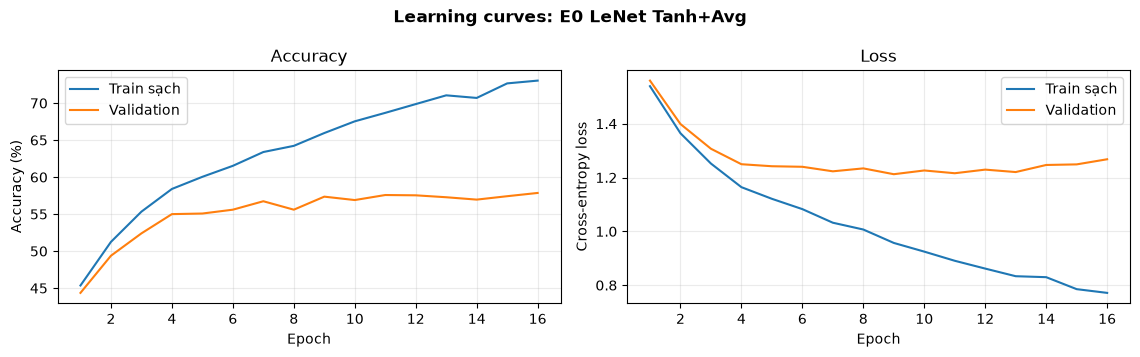


--- PHÂN TÍCH MẪU SAI TRÊN VALIDATION — E0 LeNet Tanh+Avg ---
Sai 2132/5000 mẫu (42.64%); đúng 57.36%.


In [7]:
result_E0 = run_experiment("E0 LeNet Tanh+Avg", lambda: LeNet(activation="tanh", pool="avg"), use_aug=False, wd=0.0)



=== E1 LeNet ReLU+Max ===
params=62,006 | augmentation=False | weight_decay=0 | lr=0.001 | epochs=16
epoch | opt_loss | train_loss | train_acc | val_loss | val_acc | best
------------------------------------------------------------------------------
01/16 | 1.6148   | 1.3882     | 49.88%  | 1.3987   | 49.18%  | *
02/16 | 1.3320   | 1.2660     | 54.36%  | 1.2818   | 54.18%  | *
03/16 | 1.2047   | 1.1068     | 60.38%  | 1.1600   | 58.42%  | *
04/16 | 1.1190   | 1.1007     | 60.91%  | 1.1716   | 58.88%  | 
05/16 | 1.0433   | 0.9860     | 65.08%  | 1.0691   | 61.82%  | *
06/16 | 0.9911   | 0.9332     | 67.16%  | 1.0593   | 62.88%  | *
07/16 | 0.9393   | 0.8914     | 68.26%  | 1.0507   | 63.44%  | *
08/16 | 0.8899   | 0.8260     | 70.78%  | 1.0282   | 64.26%  | *
09/16 | 0.8516   | 0.7944     | 71.96%  | 1.0259   | 65.04%  | *
10/16 | 0.8142   | 0.7690     | 72.91%  | 1.0343   | 65.60%  | 
11/16 | 0.7830   | 0.6994     | 75.31%  | 1.0083   | 66.22%  | *
12/16 | 0.7482   | 0.6618     | 77.0

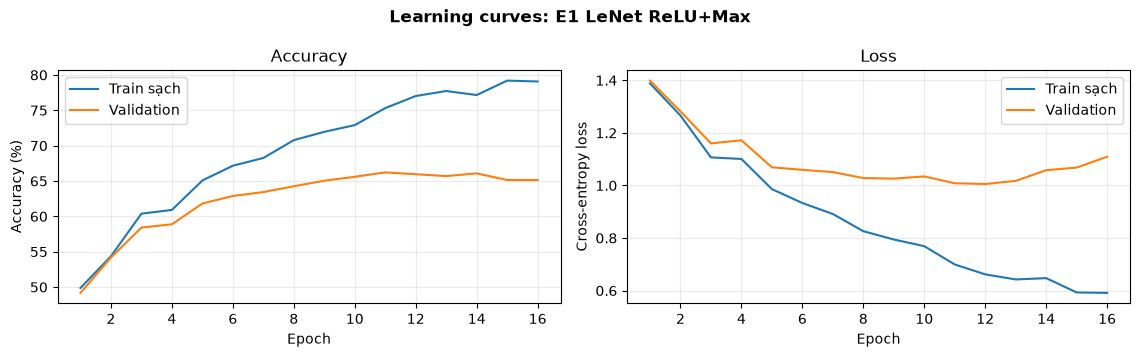


--- PHÂN TÍCH MẪU SAI TRÊN VALIDATION — E1 LeNet ReLU+Max ---
Sai 1702/5000 mẫu (34.04%); đúng 65.96%.


In [8]:
result_E1 = run_experiment("E1 LeNet ReLU+Max", lambda: LeNet(activation="relu", pool="max"), use_aug=False, wd=0.0)



=== E2 LeNet +Dropout+WD ===
params=62,006 | augmentation=False | weight_decay=0.001 | lr=0.001 | epochs=16
epoch | opt_loss | train_loss | train_acc | val_loss | val_acc | best
------------------------------------------------------------------------------
01/16 | 1.7437   | 1.4346     | 47.56%  | 1.4453   | 46.92%  | *
02/16 | 1.4683   | 1.3068     | 53.05%  | 1.3300   | 52.32%  | *
03/16 | 1.3594   | 1.1999     | 57.60%  | 1.2252   | 56.90%  | *
04/16 | 1.2878   | 1.1376     | 59.75%  | 1.1823   | 58.92%  | *
05/16 | 1.2354   | 1.0923     | 61.25%  | 1.1418   | 59.92%  | *
06/16 | 1.1965   | 1.0546     | 62.33%  | 1.1095   | 60.66%  | *
07/16 | 1.1599   | 1.0074     | 64.33%  | 1.0863   | 62.04%  | *
08/16 | 1.1341   | 0.9810     | 65.27%  | 1.0654   | 62.32%  | *
09/16 | 1.1119   | 0.9932     | 64.64%  | 1.0888   | 62.00%  | 
10/16 | 1.0878   | 0.9240     | 67.36%  | 1.0364   | 63.32%  | *
11/16 | 1.0760   | 0.9128     | 67.70%  | 1.0257   | 63.02%  | *
12/16 | 1.0520   | 0.8954   

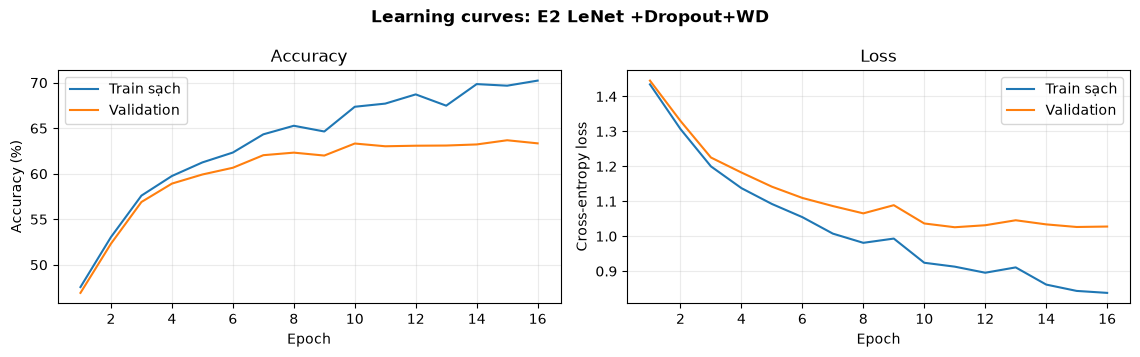


--- PHÂN TÍCH MẪU SAI TRÊN VALIDATION — E2 LeNet +Dropout+WD ---
Sai 1849/5000 mẫu (36.98%); đúng 63.02%.


In [9]:
result_E2 = run_experiment("E2 LeNet +Dropout+WD", lambda: LeNet(activation="relu", pool="max", dropout=.35), use_aug=False, wd=1e-3)



=== E3 LeNet +Augmentation ===
params=62,006 | augmentation=True | weight_decay=0.001 | lr=0.001 | epochs=16
epoch | opt_loss | train_loss | train_acc | val_loss | val_acc | best
------------------------------------------------------------------------------
01/16 | 1.8478   | 1.5089     | 44.60%  | 1.5075   | 44.54%  | *
02/16 | 1.6057   | 1.3982     | 49.24%  | 1.4009   | 48.86%  | *
03/16 | 1.5152   | 1.3487     | 52.15%  | 1.3531   | 51.26%  | *
04/16 | 1.4538   | 1.2467     | 55.60%  | 1.2476   | 55.18%  | *
05/16 | 1.4192   | 1.2127     | 57.20%  | 1.2027   | 57.34%  | *
06/16 | 1.3879   | 1.1761     | 58.35%  | 1.1669   | 57.74%  | *
07/16 | 1.3622   | 1.2118     | 57.01%  | 1.1992   | 57.72%  | 
08/16 | 1.3397   | 1.1540     | 59.18%  | 1.1582   | 59.04%  | *
09/16 | 1.3258   | 1.1240     | 60.76%  | 1.1187   | 61.16%  | *
10/16 | 1.3071   | 1.0896     | 61.53%  | 1.0900   | 62.40%  | *
11/16 | 1.2923   | 1.0802     | 62.25%  | 1.0782   | 62.74%  | *
12/16 | 1.2782   | 1.1042  

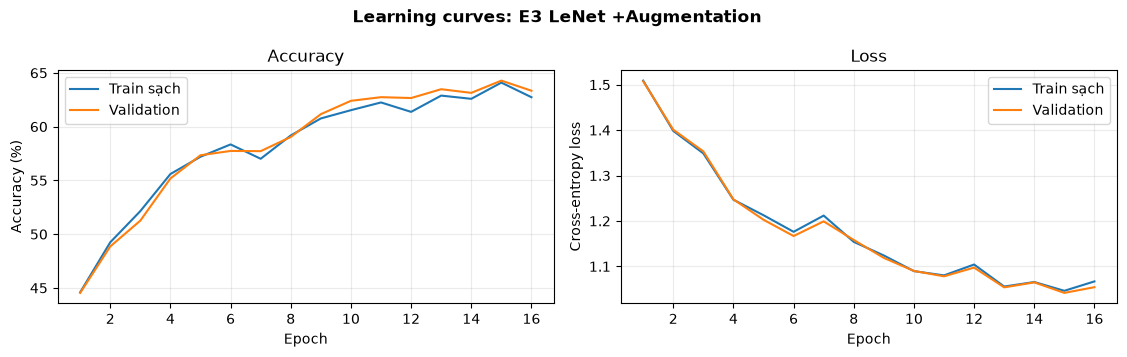


--- PHÂN TÍCH MẪU SAI TRÊN VALIDATION — E3 LeNet +Augmentation ---
Sai 1786/5000 mẫu (35.72%); đúng 64.28%.


In [10]:
result_E3 = run_experiment("E3 LeNet +Augmentation", lambda: LeNet(activation="relu", pool="max", dropout=.35), use_aug=True, wd=1e-3)



=== E4 LeNet +BatchNorm ===
params=62,050 | augmentation=True | weight_decay=0.001 | lr=0.001 | epochs=16
epoch | opt_loss | train_loss | train_acc | val_loss | val_acc | best
------------------------------------------------------------------------------
01/16 | 1.7994   | 1.5039     | 43.12%  | 1.5116   | 42.38%  | *
02/16 | 1.6006   | 1.4066     | 47.85%  | 1.4055   | 47.30%  | *
03/16 | 1.5247   | 1.3299     | 51.20%  | 1.3219   | 52.10%  | *
04/16 | 1.4774   | 1.3031     | 52.84%  | 1.3056   | 52.32%  | *
05/16 | 1.4412   | 1.2348     | 55.09%  | 1.2333   | 55.48%  | *
06/16 | 1.4073   | 1.2596     | 54.57%  | 1.2477   | 55.38%  | 
07/16 | 1.3905   | 1.1947     | 57.43%  | 1.1942   | 57.68%  | *
08/16 | 1.3738   | 1.1551     | 58.61%  | 1.1511   | 58.84%  | *
09/16 | 1.3507   | 1.1212     | 59.81%  | 1.1160   | 59.90%  | *
10/16 | 1.3354   | 1.1576     | 58.58%  | 1.1530   | 58.44%  | 
11/16 | 1.3216   | 1.1080     | 59.75%  | 1.0992   | 59.88%  | *
12/16 | 1.3144   | 1.0970     |

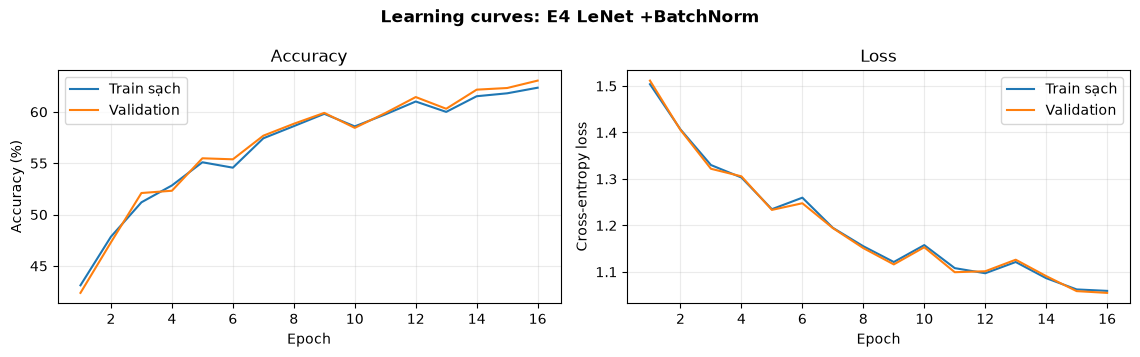


--- PHÂN TÍCH MẪU SAI TRÊN VALIDATION — E4 LeNet +BatchNorm ---
Sai 1848/5000 mẫu (36.96%); đúng 63.04%.


In [11]:
result_E4 = run_experiment("E4 LeNet +BatchNorm", lambda: LeNet(activation="relu", pool="max", batchnorm=True, dropout=.35), use_aug=True, wd=1e-3)


## 7. Modern CNN — Chạy thí nghiệm M1–M3



=== M1 VGG-tiny ===
params=77,114 | augmentation=True | weight_decay=0.001 | lr=0.001 | epochs=16
epoch | opt_loss | train_loss | train_acc | val_loss | val_acc | best
------------------------------------------------------------------------------
01/16 | 1.5105   | 1.4077     | 52.13%  | 1.3615   | 54.28%  | *
02/16 | 1.1445   | 0.9959     | 63.29%  | 0.9922   | 63.70%  | *
03/16 | 1.0087   | 0.9442     | 66.48%  | 0.9447   | 65.82%  | *
04/16 | 0.9226   | 0.7890     | 71.70%  | 0.8004   | 71.36%  | *
05/16 | 0.8532   | 0.7256     | 74.24%  | 0.7494   | 74.02%  | *
06/16 | 0.8084   | 0.7094     | 75.07%  | 0.7235   | 75.84%  | *
07/16 | 0.7674   | 0.6920     | 75.40%  | 0.7166   | 75.12%  | *
08/16 | 0.7377   | 0.6906     | 76.17%  | 0.7065   | 75.40%  | *
09/16 | 0.7128   | 0.7103     | 75.20%  | 0.7334   | 74.66%  | 
10/16 | 0.6837   | 0.6319     | 78.08%  | 0.6674   | 76.66%  | *
11/16 | 0.6700   | 0.6572     | 77.05%  | 0.6807   | 76.68%  | 
12/16 | 0.6487   | 0.6059     | 79.02% 

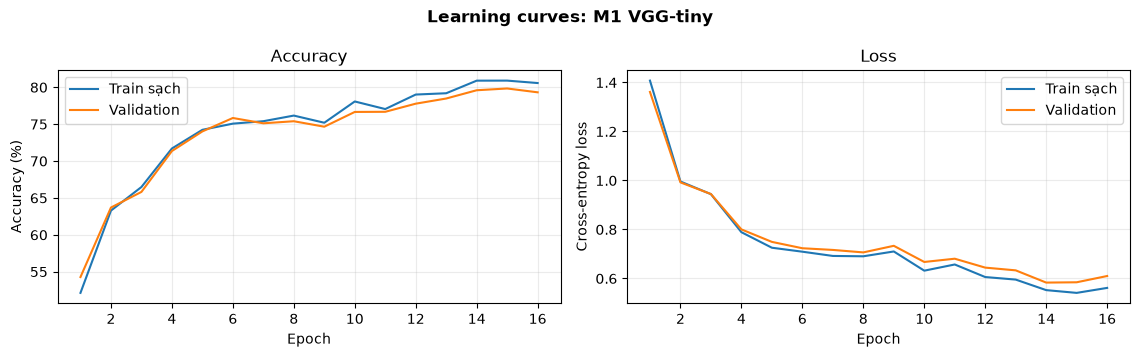


--- PHÂN TÍCH MẪU SAI TRÊN VALIDATION — M1 VGG-tiny ---
Sai 1020/5000 mẫu (20.40%); đúng 79.60%.


In [12]:
result_M1 = run_experiment("M1 VGG-tiny", VGGTiny, use_aug=True, wd=1e-3)



=== M2 Inception-tiny ===
params=27,850 | augmentation=True | weight_decay=0.001 | lr=0.001 | epochs=16
epoch | opt_loss | train_loss | train_acc | val_loss | val_acc | best
------------------------------------------------------------------------------
01/16 | 1.5870   | 1.2398     | 55.35%  | 1.2395   | 55.36%  | *
02/16 | 1.2333   | 1.0763     | 61.71%  | 1.0774   | 62.36%  | *
03/16 | 1.1189   | 0.9745     | 65.34%  | 0.9693   | 65.76%  | *
04/16 | 1.0457   | 0.9559     | 65.69%  | 0.9587   | 65.64%  | *
05/16 | 0.9985   | 0.9641     | 65.93%  | 0.9391   | 66.92%  | *
06/16 | 0.9653   | 0.8580     | 69.40%  | 0.8568   | 70.22%  | *
07/16 | 0.9314   | 0.8503     | 69.59%  | 0.8587   | 69.96%  | 
08/16 | 0.9021   | 0.8266     | 70.65%  | 0.8455   | 70.90%  | *
09/16 | 0.8839   | 0.7563     | 73.03%  | 0.7671   | 73.18%  | *
10/16 | 0.8661   | 0.7470     | 73.58%  | 0.7670   | 73.42%  | *
11/16 | 0.8420   | 0.7572     | 73.18%  | 0.7692   | 73.24%  | 
12/16 | 0.8337   | 0.6751     | 7

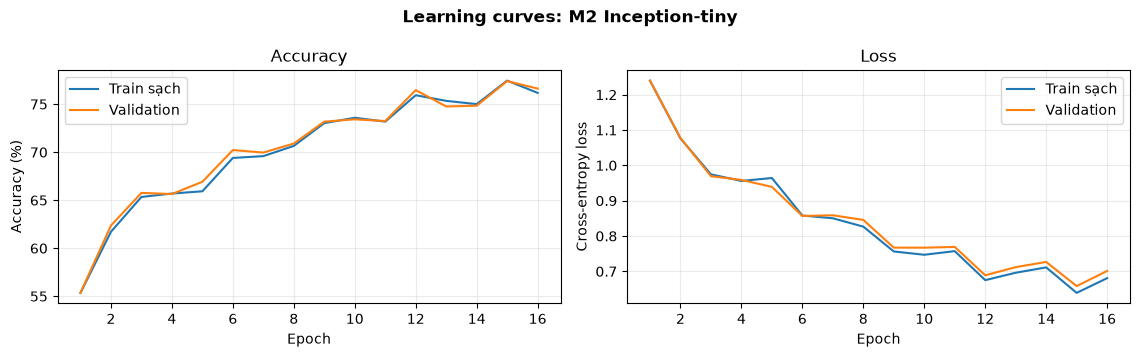


--- PHÂN TÍCH MẪU SAI TRÊN VALIDATION — M2 Inception-tiny ---
Sai 1130/5000 mẫu (22.60%); đúng 77.40%.


In [13]:
result_M2 = run_experiment("M2 Inception-tiny", InceptionTiny, use_aug=True, wd=1e-3)



=== M3 ResNet-tiny ===
params=170,586 | augmentation=True | weight_decay=0.001 | lr=0.001 | epochs=16
epoch | opt_loss | train_loss | train_acc | val_loss | val_acc | best
------------------------------------------------------------------------------
01/16 | 1.4428   | 1.2252     | 55.59%  | 1.2144   | 56.16%  | *
02/16 | 1.0536   | 1.0546     | 63.09%  | 1.0523   | 63.44%  | *
03/16 | 0.9056   | 1.1510     | 63.52%  | 1.1705   | 63.68%  | 
04/16 | 0.7947   | 0.7228     | 74.79%  | 0.7274   | 74.44%  | *
05/16 | 0.7234   | 0.7680     | 73.61%  | 0.7843   | 73.66%  | 
06/16 | 0.6742   | 0.6452     | 78.09%  | 0.6597   | 77.48%  | *
07/16 | 0.6319   | 0.6284     | 78.28%  | 0.6445   | 78.62%  | *
08/16 | 0.6024   | 0.5689     | 80.69%  | 0.6111   | 79.20%  | *
09/16 | 0.5653   | 0.5419     | 80.86%  | 0.5960   | 79.48%  | *
10/16 | 0.5453   | 0.5064     | 82.68%  | 0.5616   | 80.92%  | *
11/16 | 0.5251   | 0.5295     | 81.93%  | 0.5846   | 80.94%  | 
12/16 | 0.5062   | 0.4801     | 83.5

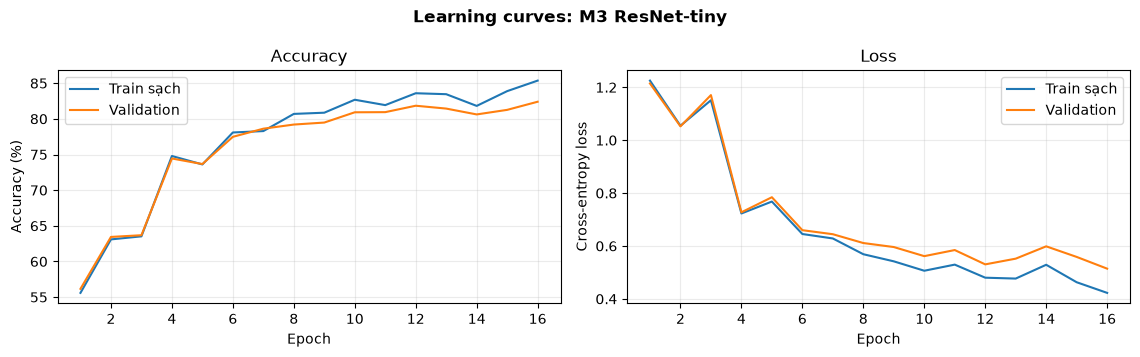


--- PHÂN TÍCH MẪU SAI TRÊN VALIDATION — M3 ResNet-tiny ---
Sai 880/5000 mẫu (17.60%); đúng 82.40%.


In [14]:
result_M3 = run_experiment("M3 ResNet-tiny", ResNetTiny, use_aug=True, wd=1e-3)


## 8. Tổng hợp 8 thí nghiệm


In [15]:
if len(RESULTS) != 8:
    raise RuntimeError(f"Cần chạy đủ 8 thí nghiệm; hiện có {len(RESULTS)}")

summary_df = pd.DataFrame(RESULTS).sort_values(["val_loss", "val_acc"], ascending=[True, False]).reset_index(drop=True)
summary_display = summary_df.copy()
for col in ["train_acc", "val_acc", "gap"]:
    summary_display[col] = (summary_display[col] * 100).round(2)
summary_display["val_loss"] = summary_display["val_loss"].round(4)
print("BẢNG TỔNG HỢP ĐỦ 8 THÍ NGHIỆM:")
display(summary_display)


BẢNG TỔNG HỢP ĐỦ 8 THÍ NGHIỆM:


,model,parameters,best_epoch,train_acc,val_acc,val_loss,gap,seconds,val_errors
0,M3 ResNet-tiny,170586,16,85.36,82.40,0.5143,2.96,1262.40,880
1,M1 VGG-tiny,77114,14,80.90,79.60,0.5833,1.30,868.63,1020
2,M2 Inception-tiny,27850,15,77.45,77.40,0.6583,0.05,2272.83,1130
3,E1 LeNet ReLU+Max,62006,12,77.02,65.96,1.0055,11.06,198.43,1702
4,E2 LeNet +Dropout+WD,62006,11,67.70,63.02,1.0257,4.68,203.86,1849
5,E3 LeNet +Augmentation,62006,15,64.10,64.28,1.0417,-0.18,354.81,1786
6,E4 LeNet +BatchNorm,62050,16,62.35,63.04,1.0547,-0.69,366.63,1848
7,E0 LeNet Tanh+Avg,62006,9,65.95,57.36,1.2123,8.59,185.03,2132


## 10. Đánh giá Test cuối cùng


In [16]:
best_name = summary_df.loc[0, "model"]
best_model = BEST_MODELS[best_name].to(DEVICE)
final_test = test_model(best_model, test_loader, criterion, DEVICE, CLASS_NAMES)

print("MÔ HÌNH CHỌN THEO VALIDATION:", best_name)
print(f"Validation loss = {summary_df.loc[0, 'val_loss']:.4f} | Validation accuracy = {summary_df.loc[0, 'val_acc']:.2%}")
print(f"TEST loss = {final_test['loss']:.4f} | TEST accuracy = {final_test['accuracy']:.2%} | n_test = {final_test['n_samples']}")
print("\nCLASSIFICATION REPORT:")
print(final_test["classification_report"])


MÔ HÌNH CHỌN THEO VALIDATION: M3 ResNet-tiny
Validation loss = 0.5143 | Validation accuracy = 82.40%
TEST loss = 0.5385 | TEST accuracy = 82.17% | n_test = 10000

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

    airplane       0.80      0.85      0.82      1000
  automobile       0.95      0.91      0.93      1000
        bird       0.68      0.81      0.74      1000
         cat       0.72      0.67      0.70      1000
        deer       0.73      0.89      0.80      1000
         dog       0.77      0.74      0.75      1000
        frog       0.90      0.76      0.83      1000
       horse       0.91      0.80      0.85      1000
        ship       0.89      0.91      0.90      1000
       truck       0.94      0.87      0.90      1000

    accuracy                           0.82     10000
   macro avg       0.83      0.82      0.82     10000
weighted avg       0.83      0.82      0.82     10000

